# 初始化模型的构建

一方面，许多主流的多因子模型当中都会考虑市值效应，另一方面，在先前的实证研究当中市值确实对策略的收益率起到了至关重要的作用，于是在构建初始化模型的时候首先考虑将市值效应加入进来，接下来我们要考虑使用什么样的代理变量来表征市值效应的暴露。在初始的尝试中我们采用较为常规的对数市值来作为市值效应的代理变量。将只考虑市值效应的模型作为M0，并且固定本次研究的股票池、训练期、测试期和训练标签，后面研究的模型完全采用同样的环境参数来比较。在本次研究当中，所有的因子都进行标准化处理，其余指标的计算也都按照标准化后的口径来进行。

### 固定研究环境

In [16]:
# Notebook 单元格 1：固定研究环境。后续模型沿用 STUDY，不在这里放模型参数。
import math
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

# 线上项目目录为 Quant_research/factor_lib；Notebook 从子目录运行时需先加入项目根目录。
_project_candidates = [Path.cwd(), Path.cwd() / "Quant_research",
                       *Path.cwd().parents, Path("/home/aiuser/work/Quant_research")]
if globals().get("PROJECT_ROOT") is not None:
    _hint = Path(globals()["PROJECT_ROOT"]).expanduser()
    _project_candidates = [_hint, _hint / "Quant_research", *_project_candidates]
PROJECT_ROOT = next(
    (path.resolve() for path in _project_candidates
     if (path / "factor_lib" / "bigquant_adapters" / "loader.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"未找到 Quant_research/factor_lib；当前工作目录：{Path.cwd()}。"
        "请确认线上项目已同步，或先设置 PROJECT_ROOT 为 Quant_research 的绝对路径。"
    )
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from factor_lib.bigquant_adapters.loader import (
    load_trading_dates, load_factor_raw_data,
)
from factor_lib.bigquant_adapters.daily import (
    DAILY_FIELD_MAPPING,
    load_daily_raw_data,
)
from factor_lib.factor_hub.get_factor import get_factor

STUDY = {
    "universe": {"type": "all_a"},
    "train_start": "2020-01-01", "train_end": "2023-12-31",
    "test_start": "2024-01-01", "test_end": "2026-06-30",
    "signal_interval_trading_days": 10,      # 相邻信号截面的交易日间隔
    "prediction_horizon_trading_days": 20,  # 从信号日到收益标签截止日的跨度
    "min_cross_section": 100,
    "top_fraction": 0.10,
    "hac_lags": None,  # 自动选阶；有效阶数至少覆盖重叠标签对应的滞后期
}
for _name in ("signal_interval_trading_days", "prediction_horizon_trading_days"):
    _value = STUDY[_name]
    if isinstance(_value, (bool, np.bool_)) or not isinstance(_value, (int, np.integer)) or _value <= 0:
        raise ValueError(f"{_name} 必须是正整数。")


### 定义模型评价函数

In [17]:
# Notebook 单元格 2：统一评价模型的样本外排序能力与15组等权收益。
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick


def evaluate_return_model(
    model_name,
    scores,
    labels,
    study,
    universe_panel=None,
    group_count=15,
):
    """评价测试期预测分数；分数越高，预测收益越高。

    Rank IC 使用 prediction_horizon_trading_days 对应的 forward_return。
    分组收益使用当前信号日到下一信号日的 signal_interval_return：
    每段先对组内股票做算术平均，再按时间逐段相加。
    """
    if not isinstance(group_count, int) or isinstance(group_count, bool) or group_count < 2:
        raise ValueError("group_count 必须是大于等于2的整数。")
    if study["universe"]["type"] != "all_a" and universe_panel is None:
        raise ValueError("自定义/指数股票池必须提供逐信号日 universe_panel。")

    score_panel = scores[["date", "instrument", "score"]].copy()
    label_columns = [
        "date", "instrument", "return_end_date", "forward_return",
        "next_signal_date", "signal_interval_return",
    ]
    missing_labels = set(label_columns) - set(labels.columns)
    if missing_labels:
        raise ValueError(f"测试标签缺少字段：{sorted(missing_labels)}")
    label_panel = labels[label_columns].copy()

    score_panel["date"] = pd.to_datetime(score_panel["date"]).dt.normalize()
    label_panel["date"] = pd.to_datetime(label_panel["date"]).dt.normalize()
    label_panel["return_end_date"] = pd.to_datetime(
        label_panel["return_end_date"]
    ).dt.normalize()
    label_panel["next_signal_date"] = pd.to_datetime(
        label_panel["next_signal_date"]
    ).dt.normalize()
    score_panel["score"] = pd.to_numeric(score_panel["score"], errors="coerce")
    label_panel["forward_return"] = pd.to_numeric(
        label_panel["forward_return"], errors="coerce"
    )
    label_panel["signal_interval_return"] = pd.to_numeric(
        label_panel["signal_interval_return"], errors="coerce"
    )

    for name, panel in (("scores", score_panel), ("labels", label_panel)):
        if panel.duplicated(["date", "instrument"]).any():
            raise ValueError(f"{name} 存在重复的 date + instrument。")

    if universe_panel is not None:
        membership = universe_panel[["date", "instrument"]].copy()
        membership["date"] = pd.to_datetime(membership["date"]).dt.normalize()
        membership = membership.drop_duplicates(["date", "instrument"])
        score_panel = score_panel.merge(
            membership, on=["date", "instrument"], how="inner", validate="one_to_one"
        )
        label_panel = label_panel.merge(
            membership, on=["date", "instrument"], how="inner", validate="one_to_one"
        )

    score_panel = score_panel.replace([np.inf, -np.inf], np.nan).dropna(
        subset=["score"]
    )

    # 每个信号日独立按预测分数等数量分组；1=最低预测，15=最高预测。
    grouped_scores = []
    for date, section in score_panel.groupby("date", sort=True):
        section = section.copy()
        if len(section) < max(study["min_cross_section"], group_count):
            raise ValueError(f"{date:%Y-%m-%d} 的有效预测股票数不足。")
        if section["score"].nunique() < 2:
            raise ValueError(f"{date:%Y-%m-%d} 的预测分数没有截面差异。")
        ordered_rank = section["score"].rank(method="first")
        section["prediction_group"] = pd.qcut(
            ordered_rank,
            q=group_count,
            labels=range(1, group_count + 1),
        ).astype(int)
        grouped_scores.append(section)
    score_panel = pd.concat(grouped_scores, ignore_index=True)

    # Rank IC：预测排名与预测窗口收益排名的逐期 Spearman 相关。
    rank_panel = score_panel.merge(
        label_panel[["date", "instrument", "return_end_date", "forward_return"]],
        on=["date", "instrument"],
        how="inner",
        validate="one_to_one",
    ).replace([np.inf, -np.inf], np.nan).dropna(
        subset=["score", "forward_return"]
    )
    rank_ic_rows = []
    for date, section in rank_panel.groupby("date", sort=True):
        if len(section) < study["min_cross_section"]:
            raise ValueError(f"{date:%Y-%m-%d} 的 Rank IC 有效股票数不足。")
        rank_ic_rows.append({
            "date": date,
            "return_end_date": section["return_end_date"].iloc[0],
            "n_stocks": len(section),
            "rank_ic": section["score"].corr(
                section["forward_return"], method="spearman"
            ),
        })
    rank_ic_series = pd.DataFrame(rank_ic_rows).dropna(subset=["rank_ic"])
    if rank_ic_series.empty:
        raise ValueError("测试期没有有效 Rank IC。")

    # 分组收益：组别在信号日形成，组内个股收益做算术平均。
    group_panel = score_panel.merge(
        label_panel[
            ["date", "instrument", "next_signal_date", "signal_interval_return"]
        ],
        on=["date", "instrument"],
        how="left",
        validate="one_to_one",
    ).replace([np.inf, -np.inf], np.nan).dropna(
        subset=["next_signal_date", "signal_interval_return"]
    )
    group_period_returns = (
        group_panel.groupby(
            ["date", "next_signal_date", "prediction_group"], as_index=False
        )
        .agg(
            period_equal_weight_return=("signal_interval_return", "mean"),
            n_stocks=("instrument", "size"),
        )
        .sort_values(["prediction_group", "date"], kind="mergesort")
        .reset_index(drop=True)
    )
    observed_groups = set(group_period_returns["prediction_group"].unique())
    expected_groups = set(range(1, group_count + 1))
    if observed_groups != expected_groups:
        raise ValueError(
            f"分组收益缺少组别：{sorted(expected_groups - observed_groups)}"
        )
    group_period_returns["cumulative_return_additive"] = (
        group_period_returns.groupby("prediction_group")[
            "period_equal_weight_return"
        ].cumsum()
    )

    final_group_returns = (
        group_period_returns.groupby("prediction_group", as_index=False).tail(1)
        .set_index("prediction_group")["cumulative_return_additive"]
    )
    summary = {
        "model": model_name,
        "rank_ic_dates": len(rank_ic_series),
        "rank_ic_mean": rank_ic_series["rank_ic"].mean(),
        "rank_ic_std": rank_ic_series["rank_ic"].std(ddof=1),
    }
    for group in range(1, group_count + 1):
        summary[f"group_{group:02d}_cumulative_return"] = final_group_returns.loc[group]
    prediction_summary = pd.DataFrame([summary])

    # 图1：Rank IC 时序。
    rank_fig, rank_ax = plt.subplots(figsize=(13.5, 4.8), dpi=120)
    rank_dates = rank_ic_series["date"]
    rank_values = rank_ic_series["rank_ic"].to_numpy(dtype=float)
    rank_ax.plot(
        rank_dates, rank_values,
        color="#315A7D", linewidth=1.8, marker="o", markersize=3.5,
        markerfacecolor="white", markeredgewidth=0.9,
    )
    rank_ax.fill_between(
        rank_dates, 0, rank_values,
        where=rank_values >= 0, color="#4C9F70", alpha=0.16,
        interpolate=True,
    )
    rank_ax.fill_between(
        rank_dates, 0, rank_values,
        where=rank_values < 0, color="#C65D64", alpha=0.14,
        interpolate=True,
    )
    rank_ax.axhline(0, color="#4A4A4A", linewidth=0.9, alpha=0.75)
    rank_ax.axhline(
        prediction_summary.loc[0, "rank_ic_mean"],
        color="#D18B2C", linewidth=1.5, linestyle="--",
        label=f'Mean = {prediction_summary.loc[0, "rank_ic_mean"]:.4f}',
    )
    rank_ax.set_title(f"{model_name}: Out-of-Sample Rank IC", fontsize=14, pad=12)
    rank_ax.set_xlabel("Signal date")
    rank_ax.set_ylabel("Rank IC")
    rank_ax.grid(axis="y", color="#D8DEE5", linewidth=0.7, alpha=0.65)
    rank_ax.grid(False, axis="x")
    rank_ax.legend(frameon=False, loc="best")
    for spine in ("top", "right"):
        rank_ax.spines[spine].set_visible(False)
    rank_fig.tight_layout()
    plt.close(rank_fig)

    # 图2：15组逐段相加的累计等权收益曲线。
    group_fig, group_ax = plt.subplots(figsize=(14.5, 7.2), dpi=120)
    color_map = plt.get_cmap("viridis")
    colors = color_map(np.linspace(0.04, 0.96, group_count))
    for group, color in zip(range(1, group_count + 1), colors):
        curve = group_period_returns.loc[
            group_period_returns["prediction_group"].eq(group)
        ]
        emphasized = group in {1, group_count}
        group_ax.plot(
            curve["next_signal_date"],
            curve["cumulative_return_additive"],
            color=color,
            linewidth=2.6 if emphasized else 1.45,
            alpha=1.0 if emphasized else 0.84,
            label=f"Group {group:02d}",
        )
    group_ax.axhline(0, color="#555555", linewidth=0.9, alpha=0.7)
    group_ax.set_title(
        f"{model_name}: 15 Prediction Groups — Additive Cumulative Returns",
        fontsize=14, pad=12,
    )
    group_ax.set_xlabel("Next signal date")
    group_ax.set_ylabel("Cumulative return (additive)")
    group_ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    group_ax.grid(axis="y", color="#D8DEE5", linewidth=0.7, alpha=0.65)
    group_ax.grid(False, axis="x")
    for spine in ("top", "right"):
        group_ax.spines[spine].set_visible(False)
    group_ax.legend(
        ncol=3, frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left",
        borderaxespad=0,
    )
    group_fig.tight_layout(rect=(0, 0, 0.84, 1))
    plt.close(group_fig)

    return {
        "prediction_summary": prediction_summary,
        "rank_ic_series": rank_ic_series,
        "group_period_returns": group_period_returns,
        "rank_ic_figure": rank_fig,
        "group_return_figure": group_fig,
    }


### 标签数据准备

In [18]:
# Notebook 单元格 3：按固定研究环境准备一次共享标签，后续模型直接复用。
calendar = load_trading_dates(STUDY["train_start"], STUDY["test_end"])
signal_interval = STUDY["signal_interval_trading_days"]
horizon = STUDY["prediction_horizon_trading_days"]
schedule_rows = []
for split in ("train", "test"):
    start = pd.Timestamp(STUDY[f"{split}_start"])
    end = pd.Timestamp(STUDY[f"{split}_end"])
    dates = calendar[(calendar >= start) & (calendar <= end)]
    sampled_dates = dates[::signal_interval]
    for position, date in enumerate(sampled_dates):
        end_position = calendar.get_loc(date) + horizon
        if end_position < len(calendar) and calendar[end_position] <= end:
            next_signal_date = (
                sampled_dates[position + 1]
                if position + 1 < len(sampled_dates)
                else pd.NaT
            )
            schedule_rows.append(
                (split, date, calendar[end_position], next_signal_date)
            )
schedule = pd.DataFrame(
    schedule_rows,
    columns=["split", "date", "return_end_date", "next_signal_date"],
)
if not {"train", "test"}.issubset(set(schedule["split"])):
    raise ValueError("训练期或测试期没有完整的未来收益标签。")
signal_dates = pd.DatetimeIndex(schedule["date"].unique())

# 股票池在信号日确定；指数股票池读取当日历史成分。
universe = STUDY["universe"]
universe_panel, instruments = None, None
if universe["type"] == "custom":
    instruments = list(universe["instruments"])
    universe_panel = pd.MultiIndex.from_product(
        [signal_dates, instruments], names=["date", "instrument"]
    ).to_frame(index=False)
elif universe["type"] == "index":
    import dai
    index_codes = ", ".join("'" + code.replace("'", "''") + "'"
                            for code in universe["index_codes"])
    date_codes = ", ".join("'" + date.strftime("%Y-%m-%d") + "'"
                           for date in signal_dates)
    universe_panel = dai.query(
        f"SELECT date, member_code AS instrument FROM cn_stock_index_component "
        f"WHERE instrument IN ({index_codes}) AND date IN ({date_codes})",
        filters={"date": [signal_dates.min().strftime("%Y-%m-%d"),
                          signal_dates.max().strftime("%Y-%m-%d")]},
    ).df()
    universe_panel["date"] = pd.to_datetime(universe_panel["date"]).dt.normalize()
    universe_panel = universe_panel.drop_duplicates(["date", "instrument"])
    if set(signal_dates) - set(universe_panel["date"]):
        raise ValueError("部分信号日没有查询到指数历史成分股。")
    instruments = universe_panel["instrument"].unique().tolist()
elif universe["type"] != "all_a":
    raise ValueError("universe.type 仅支持 all_a、custom、index。")

# 收益价格必须来自 cn_stock_bar1d.close；仓库适配器将它定义为后复权收盘价。
close_spec = DAILY_FIELD_MAPPING.get("close")
if close_spec != {"table": "bar1d", "column": "close"}:
    raise RuntimeError(
        f"close 字段映射不符合预期：{close_spec}；请检查后复权行情适配器。"
    )

# 同时准备两种后复权收益标签：
# 1. forward_return：信号日至未来 horizon 日，用于训练及 Rank IC；
# 2. signal_interval_return：信号日至下一信号日，用于动态分组收益。
next_signal_dates = set(schedule["next_signal_date"].dropna())
price_dates = sorted(
    set(schedule["date"])
    | set(schedule["return_end_date"])
    | next_signal_dates
)
prices = load_daily_raw_data(
    ["close"], dates=price_dates, instruments=instruments, show_progress=True,
)
prices["date"] = pd.to_datetime(prices["date"]).dt.normalize()
prices["close"] = pd.to_numeric(prices["close"], errors="coerce")
prices = prices.loc[prices["close"].gt(0)]
if prices.duplicated(["date", "instrument"]).any():
    raise ValueError("价格存在重复的 date + instrument。")
labels = schedule.merge(
    prices.rename(columns={"close": "start_close"}),
    on="date", validate="one_to_many",
).merge(
    prices.rename(columns={"date": "return_end_date", "close": "end_close"}),
    on=["return_end_date", "instrument"], validate="one_to_one",
)
labels["forward_return"] = labels["end_close"] / labels["start_close"] - 1
labels = labels.merge(
    prices.rename(
        columns={"date": "next_signal_date", "close": "next_signal_close"}
    ),
    on=["next_signal_date", "instrument"],
    how="left",
    validate="many_to_one",
)
labels["signal_interval_return"] = (
    labels["next_signal_close"] / labels["start_close"] - 1
)
labels = labels[
    [
        "split", "date", "instrument", "return_end_date", "forward_return",
        "next_signal_date", "signal_interval_return",
    ]
]
if universe_panel is not None:
    labels = labels.merge(universe_panel, on=["date", "instrument"],
                          validate="one_to_one")

train_labels = labels.loc[labels["split"].eq("train")].copy()
test_labels = labels.loc[labels["split"].eq("test")].copy()
if train_labels.empty or test_labels.empty:
    raise ValueError("训练期或测试期标签为空，请检查日期、股票池和价格覆盖。")
print(f"共享标签准备完成：训练期 {len(train_labels):,} 条，"
      f"测试期 {len(test_labels):,} 条；后续模型无需重复查询标签价格。")


[BigQuant 日频适配器] [3/3] 查询结果校验完成 | 1/1 (100.0%) | 774,593 行 | 已耗时 0.9s                                                                                                               
共享标签准备完成：训练期 431,288 条，测试期 317,511 条；后续模型无需重复查询标签价格。


### 构建与评价M0

[BigQuant 日频适配器] [1/3] 准备日频查询 | 154 个离散日期（2020-01-02 至 2026-06-01），1 个字段 | 已耗时 0.0s                                                                                                 

[BigQuant 日频适配器] [3/3] 查询结果校验完成 | 1/1 (100.0%) | 752,855 行 | 已耗时 1.0s                                                                                                               
[BigQuant loader] 1/1（100.00%），数据域合并完成，当前 security_daily，752,855 行，耗时 1.3s                                                                                                         
[log_market_cap] [2/2] 完成 | 耗时 0.4s


,intercept,log_market_cap_slope
model,,
M0,0.008880,-0.005804


,rank_ic_dates,rank_ic_mean,rank_ic_std,group_01_cumulative_return,group_02_cumulative_return,group_03_cumulative_return,group_04_cumulative_return,group_05_cumulative_return,group_06_cumulative_return,group_07_cumulative_return,group_08_cumulative_return,group_09_cumulative_return,group_10_cumulative_return,group_11_cumulative_return,group_12_cumulative_return,group_13_cumulative_return,group_14_cumulative_return,group_15_cumulative_return
model,,,,,,,,,,,,,,,,,,
M0,59,0.0277,0.2358,48.39%,47.43%,37.96%,37.69%,45.41%,30.79%,40.19%,35.62%,32.17%,52.52%,46.50%,56.69%,54.79%,65.57%,103.39%


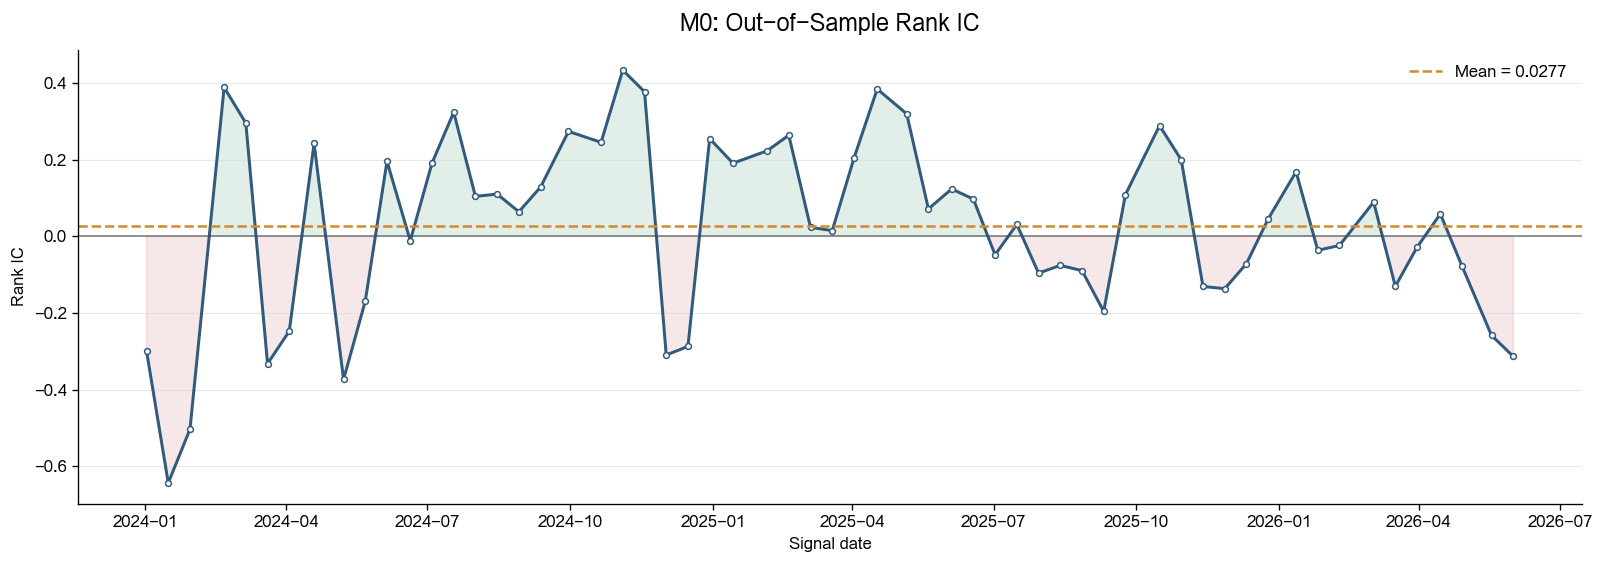

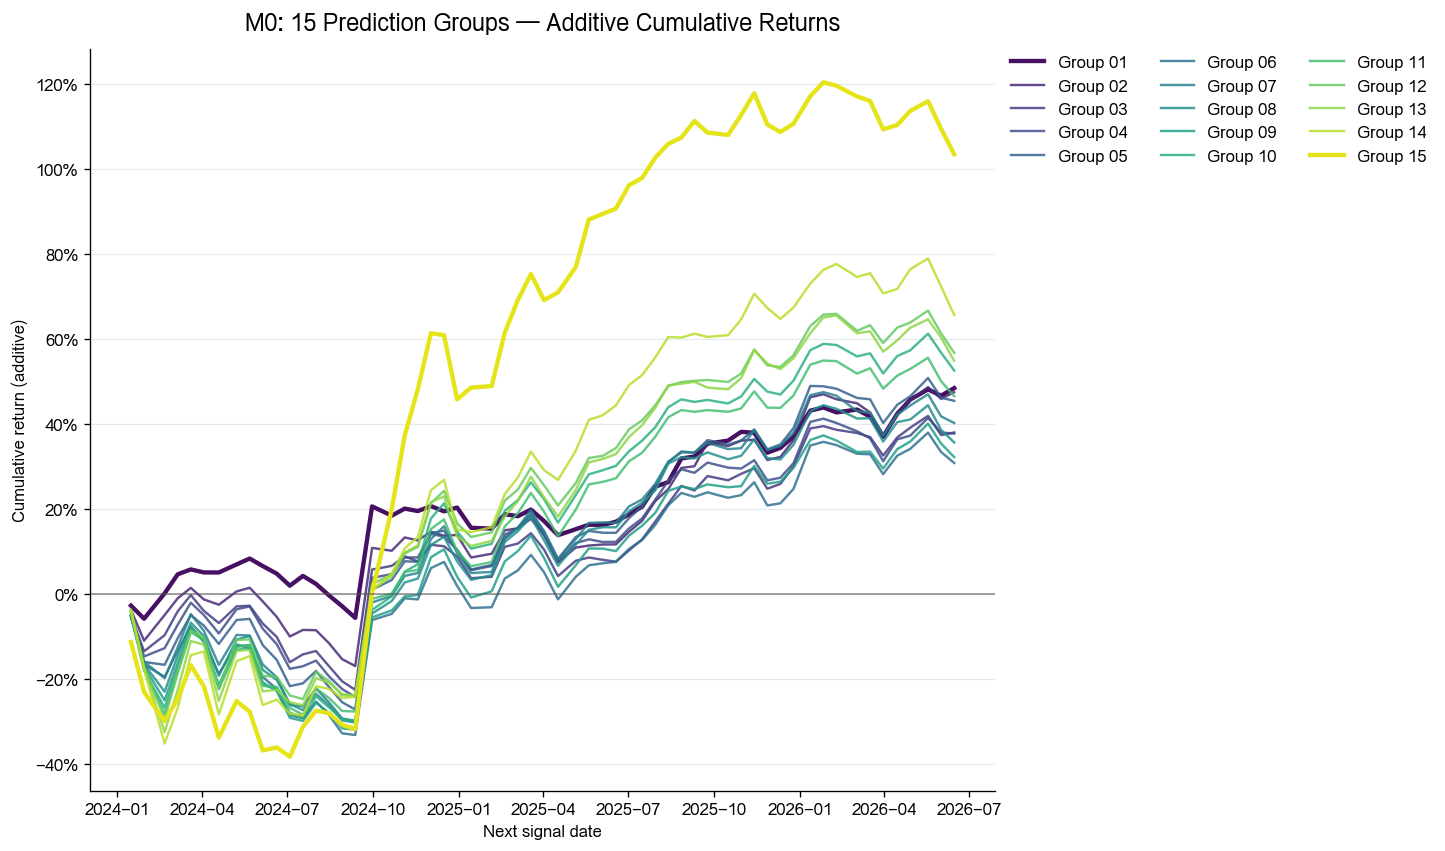

In [19]:
# Notebook 单元格 4：在训练集拟合 M0，在测试集评价，并按四行展示结果。
MODEL = {
    "name": "M0",
    "factor_name": "log_market_cap",
    "feature_column": "log_market_cap_z",
}

# 1. 获取全部训练/测试信号日的对数市值，并在每个截面单独标准化。
raw = load_factor_raw_data(
    MODEL["factor_name"],
    dates=signal_dates,
    factor_params={},
    instruments=instruments,
    show_progress=True,
)
factor = get_factor(
    MODEL["factor_name"],
    raw,
    target_dates=signal_dates,
    as_of_date=STUDY["test_end"],
    show_progress=True,
)
factor["date"] = pd.to_datetime(factor["date"]).dt.normalize()
if factor.duplicated(["date", "instrument"]).any():
    raise ValueError("对数市值特征存在重复的 date + instrument。")
if universe_panel is not None:
    factor = factor.merge(
        universe_panel,
        on=["date", "instrument"],
        how="inner",
        validate="one_to_one",
    )
factor[MODEL["factor_name"]] = pd.to_numeric(
    factor[MODEL["factor_name"]], errors="coerce"
)
factor[MODEL["feature_column"]] = factor.groupby("date")[
    MODEL["factor_name"]
].transform(
    lambda values: (values - values.mean()) / values.std(ddof=0)
    if values.std(ddof=0) > 0 else np.nan
)

# 2. 仅用训练集逐期做截面回归；固定模型参数为逐期系数的时间均值。
train_panel = factor[["date", "instrument", MODEL["feature_column"]]].merge(
    train_labels[["date", "instrument", "forward_return"]],
    on=["date", "instrument"],
    how="inner",
    validate="one_to_one",
).replace([np.inf, -np.inf], np.nan).dropna(
    subset=[MODEL["feature_column"], "forward_return"]
)

coefficient_rows = []
for date, section in train_panel.groupby("date", sort=True):
    if len(section) < STUDY["min_cross_section"]:
        raise ValueError(f"训练截面 {date:%Y-%m-%d} 的有效股票数不足。")
    x = section[MODEL["feature_column"]].to_numpy(dtype=float)
    y = section["forward_return"].to_numpy(dtype=float)
    design = np.column_stack([np.ones(len(section)), x])
    if np.linalg.matrix_rank(design) != 2:
        raise ValueError(f"训练截面 {date:%Y-%m-%d} 的设计矩阵不满秩。")
    intercept_t, slope_t = np.linalg.lstsq(design, y, rcond=None)[0]
    coefficient_rows.append({
        "date": date,
        "intercept": intercept_t,
        f"{MODEL['factor_name']}_slope": slope_t,
    })

coefficient_timeseries = pd.DataFrame(coefficient_rows)
if coefficient_timeseries.empty:
    raise ValueError("训练期没有得到有效模型参数。")
model_intercept = float(coefficient_timeseries["intercept"].mean())
model_slope = float(
    coefficient_timeseries[f"{MODEL['factor_name']}_slope"].mean()
)
if not np.isfinite(model_intercept) or not np.isfinite(model_slope):
    raise ValueError("M0 的训练期平均参数无效。")

m0_parameters = pd.DataFrame([{
    "model": MODEL["name"],
    "intercept": model_intercept,
    f"{MODEL['factor_name']}_slope": model_slope,
}])

# 3. 测试集只使用固定参数和当期特征形成预测分数。
test_dates = pd.DatetimeIndex(test_labels["date"].unique()).sort_values()
m0_scores = factor.loc[
    factor["date"].isin(test_dates),
    ["date", "instrument", MODEL["feature_column"]],
].copy()
m0_scores["score"] = (
    model_intercept
    + model_slope * m0_scores[MODEL["feature_column"]]
)
m0_scores = m0_scores[["date", "instrument", "score"]]

# 供后续自动筛选 M1、M2 等模型复用的已选特征面板。
# 每个特征列都应是按信号日标准化后的截面暴露。
m0_selected_feature_panels = {
    MODEL["factor_name"]: factor[
        ["date", "instrument", MODEL["feature_column"]]
    ].rename(columns={MODEL["feature_column"]: MODEL["factor_name"]}).copy()
}

# 4. 评价测试期 Rank IC 和15个动态预测分组的等权累计收益。
m0_evaluation = evaluate_return_model(
    model_name=MODEL["name"],
    scores=m0_scores,
    labels=test_labels,
    study=STUDY,
    universe_panel=universe_panel,
    group_count=15,
)

# 最终按四行展示：
# 1）模型参数；2）测试期预测能力；3）Rank IC 时序；4）15组收益曲线。
parameter_format = {
    "intercept": "{:.6f}",
    f"{MODEL['factor_name']}_slope": "{:.6f}",
}
summary_format = {
    "rank_ic_mean": "{:.4f}",
    "rank_ic_std": "{:.4f}",
    **{
        f"group_{group:02d}_cumulative_return": "{:.2%}"
        for group in range(1, 16)
    },
}

display(
    m0_parameters.set_index("model")
    .style.format(parameter_format)
    .set_caption("1. Model parameters estimated from the training set")
)
display(
    m0_evaluation["prediction_summary"].set_index("model")
    .style.format(summary_format)
    .set_caption(
        "2. Out-of-sample prediction ability "
        "(Group 01 = lowest score, Group 15 = highest score)"
    )
)
display(m0_evaluation["rank_ic_figure"])
display(m0_evaluation["group_return_figure"])


### M1因子筛选

In [20]:
# Notebook 单元格 5：在训练期内部滚动筛选 M0 之后的下一个因子。
#
# 选择依据是候选因子加入已有模型后的增量样本外 Rank IC。
# 测试期标签和测试期特征不参与本单元格的候选选择。

from collections.abc import Mapping

from factor_lib.bigquant_adapters.loader import get_factor_data_requirements
from factor_lib.factor_hub.discover_factors import discover_factors


M1_SELECTION_CONFIG = {
    # 当前信号间隔为10个交易日；48期约对应两年完整历史。
    "min_train_signal_dates": 48,
    # 候选因子至少需要留下这么多滚动验证日，才进入最终排名。
    "min_validation_dates": 24,
    # 候选因子在已有模型可用股票中的平均覆盖率下限。
    "minimum_feature_coverage": 0.80,
    # None 表示扫描全部已登记 base 因子及其 candidate_instances。
    # 也可写成如 ["book_to_price", "qfa_roe"] 的白名单。
    "candidate_names": None,
    "show_progress": True,
}


def _normalize_selection_config(config):
    defaults = {
        "min_train_signal_dates": 48,
        "min_validation_dates": 24,
        "minimum_feature_coverage": 0.80,
        "candidate_names": None,
        "show_progress": True,
    }
    result = dict(defaults)
    if config is not None:
        result.update(dict(config))
    for name in ("min_train_signal_dates", "min_validation_dates"):
        value = result[name]
        if isinstance(value, bool) or not isinstance(value, int) or value <= 0:
            raise ValueError(f"{name} 必须是正整数。")
    coverage = result["minimum_feature_coverage"]
    if not isinstance(coverage, (int, float)) or not 0 < coverage <= 1:
        raise ValueError("minimum_feature_coverage 必须在 (0, 1] 内。")
    if result["candidate_names"] is not None:
        result["candidate_names"] = set(result["candidate_names"])
    if not isinstance(result["show_progress"], bool):
        raise ValueError("show_progress 必须是 bool。")
    return result


def _expand_candidate_instances(factor_name, metadata):
    """将 FACTOR['candidate_instances'] 统一展开为参数版本列表。"""
    instances = metadata.get("candidate_instances", {"default": {}})
    result = []
    if isinstance(instances, Mapping):
        for instance_id, params in instances.items():
            if not isinstance(params, Mapping):
                raise TypeError(
                    f"{factor_name} 的实例 {instance_id!r} 参数必须是字典。"
                )
            result.append((str(instance_id), dict(params)))
    elif isinstance(instances, list):
        for item in instances:
            if not isinstance(item, Mapping):
                raise TypeError(f"{factor_name} 的 candidate_instances 项必须是字典。")
            instance_id = item.get("id")
            params = item.get("params", {})
            if not instance_id or not isinstance(params, Mapping):
                raise ValueError(f"{factor_name} 的 candidate_instances 项缺少 id 或 params。")
            result.append((str(instance_id), dict(params)))
    else:
        raise TypeError(f"{factor_name} 的 candidate_instances 格式不支持。")
    return result or [("default", {})]


def _resolve_factor_output_column(factor_name, metadata, panel):
    output_schema = metadata.get("output_schema", {})
    declared = [
        column for column in output_schema
        if column not in {"date", "instrument"}
    ]
    if factor_name in panel.columns:
        return factor_name
    available = [column for column in declared if column in panel.columns]
    if len(available) == 1:
        return available[0]
    numeric = [
        column for column in panel.columns
        if column not in {"date", "instrument"}
    ]
    if len(numeric) == 1:
        return numeric[0]
    raise ValueError(
        f"无法确定因子 {factor_name!r} 的输出列；可用列：{numeric}"
    )


def _merge_feature_panels(feature_panels):
    """将已选特征面板合并为一个 date + instrument 截面。"""
    if not isinstance(feature_panels, Mapping) or not feature_panels:
        raise ValueError("selected_feature_panels 必须是非空字典。")
    merged = None
    for feature_name, panel in feature_panels.items():
        required = {"date", "instrument", feature_name}
        missing = required - set(panel.columns)
        if missing:
            raise ValueError(
                f"已选特征 {feature_name!r} 缺少字段：{sorted(missing)}"
            )
        current = panel[["date", "instrument", feature_name]].copy()
        current["date"] = pd.to_datetime(current["date"]).dt.normalize()
        if current.duplicated(["date", "instrument"]).any():
            raise ValueError(f"已选特征 {feature_name!r} 存在重复键。")
        merged = (
            current
            if merged is None
            else merged.merge(
                current,
                on=["date", "instrument"],
                how="inner",
                validate="one_to_one",
            )
        )
    return merged


def _standardize_factor_panel(panel, source_column, feature_name):
    """每个信号日独立 z-score；只使用当期截面因子值。"""
    result = panel[["date", "instrument", source_column]].copy()
    result["date"] = pd.to_datetime(result["date"]).dt.normalize()
    result[source_column] = pd.to_numeric(result[source_column], errors="coerce")
    if result.duplicated(["date", "instrument"]).any():
        raise ValueError(f"候选特征 {feature_name!r} 存在重复键。")
    result[feature_name] = result.groupby("date")[source_column].transform(
        lambda values: (
            (values - values.mean()) / values.std(ddof=0)
            if values.std(ddof=0) > 0 else np.nan
        )
    )
    return result[["date", "instrument", feature_name]]


def _raw_dates_for_factor(target_dates, full_calendar, data_window):
    lookback = max(
        int(data_window.get("lookback_trading_days", 0)),
        int(data_window.get("minimum_history_observations", 0)),
    )
    positions = {date: position for position, date in enumerate(full_calendar)}
    target_dates = pd.DatetimeIndex(target_dates).normalize().sort_values()
    if target_dates.empty:
        raise ValueError("候选筛选缺少训练期目标日期。")
    first_position = positions.get(target_dates.min())
    last_position = positions.get(target_dates.max())
    if first_position is None or last_position is None:
        raise ValueError("训练期目标日期不在预热交易日历中。")
    if first_position < lookback:
        raise ValueError(
            f"最早训练日期缺少 {lookback} 个交易日的因子预热数据。"
        )
    return full_calendar[first_position - lookback:last_position + 1]


def _cross_sectional_coefficients(feature_panel, labels, feature_columns, min_obs):
    """逐期截面 OLS，返回每期参数及该期标签结束日。"""
    panel = feature_panel.merge(
        labels[["date", "instrument", "return_end_date", "forward_return"]],
        on=["date", "instrument"],
        how="inner",
        validate="one_to_one",
    ).replace([np.inf, -np.inf], np.nan).dropna(
        subset=[*feature_columns, "forward_return"]
    )
    rows = []
    for date, section in panel.groupby("date", sort=True):
        if len(section) < min_obs:
            continue
        x = section[feature_columns].to_numpy(dtype=float)
        design = np.column_stack([np.ones(len(section)), x])
        if np.linalg.matrix_rank(design) != len(feature_columns) + 1:
            continue
        beta = np.linalg.lstsq(
            design,
            section["forward_return"].to_numpy(dtype=float),
            rcond=None,
        )[0]
        row = {
            "date": date,
            "return_end_date": section["return_end_date"].iloc[0],
            "intercept": beta[0],
        }
        row.update(dict(zip(feature_columns, beta[1:])))
        rows.append(row)
    return pd.DataFrame(rows)


def _mean_parameters_before(coefficients, validation_date, feature_columns, minimum_dates):
    """只使用收益标签在验证日前已经结束的历史参数。"""
    past = coefficients.loc[
        coefficients["return_end_date"].lt(validation_date),
        ["intercept", *feature_columns],
    ]
    if len(past) < minimum_dates:
        return None
    return past.mean()


def _score_at_date(feature_panel, feature_columns, parameters, date):
    section = feature_panel.loc[
        feature_panel["date"].eq(date),
        ["date", "instrument", *feature_columns],
    ].dropna(subset=feature_columns).copy()
    if section.empty:
        return pd.DataFrame(columns=["date", "instrument", "score"])
    section["score"] = (
        float(parameters["intercept"])
        + section[feature_columns].to_numpy(dtype=float)
        @ parameters[feature_columns].to_numpy(dtype=float)
    )
    return section[["date", "instrument", "score"]]


def _rank_ic(scores, labels, date, min_obs):
    section = scores.merge(
        labels.loc[
            labels["date"].eq(date),
            ["date", "instrument", "forward_return"],
        ],
        on=["date", "instrument"],
        how="inner",
        validate="one_to_one",
    ).replace([np.inf, -np.inf], np.nan).dropna(
        subset=["score", "forward_return"]
    )
    if len(section) < min_obs or section["score"].nunique() < 2:
        return np.nan
    return section["score"].corr(section["forward_return"], method="spearman")


def _mean_candidate_coverage(base_panel, candidate_panel, dates):
    ratios = []
    for date in dates:
        base_count = base_panel.loc[base_panel["date"].eq(date)].dropna().shape[0]
        candidate_count = candidate_panel.loc[
            candidate_panel["date"].eq(date)
        ].dropna().shape[0]
        if base_count:
            ratios.append(candidate_count / base_count)
    return float(np.mean(ratios)) if ratios else np.nan


def _median_abs_correlation(base_panel, candidate_panel, base_features, candidate_feature):
    merged = base_panel.merge(
        candidate_panel,
        on=["date", "instrument"],
        how="inner",
        validate="one_to_one",
    )
    correlations = []
    for _, section in merged.groupby("date", sort=True):
        for base_feature in base_features:
            valid = section[[base_feature, candidate_feature]].dropna()
            if len(valid) >= 3 and valid[base_feature].nunique() > 1:
                correlations.append(
                    abs(valid[base_feature].corr(valid[candidate_feature], method="spearman"))
                )
    return float(np.nanmedian(correlations)) if correlations else np.nan


def screen_next_factor(
    selected_feature_panels,
    train_labels,
    train_signal_dates,
    trading_calendar,
    study,
    instruments=None,
    universe_panel=None,
    config=None,
):
    """在训练期内部做扩张窗口验证，自动筛选下一个增量因子。

    返回的 ranking 按 operational_delta_rank_ic_mean 排序；
    common_delta_rank_ic_mean 供检查候选因子是否仅因覆盖股票变化而看似提升。
    """
    cfg = _normalize_selection_config(config)
    selected_feature_panels = dict(selected_feature_panels)
    selected_features = list(selected_feature_panels)
    base_panel = _merge_feature_panels(selected_feature_panels)
    base_panel = base_panel.loc[
        base_panel["date"].isin(pd.DatetimeIndex(train_signal_dates))
    ].copy()
    train_labels = train_labels[
        ["date", "instrument", "return_end_date", "forward_return"]
    ].copy()
    train_labels["date"] = pd.to_datetime(train_labels["date"]).dt.normalize()
    train_labels["return_end_date"] = pd.to_datetime(
        train_labels["return_end_date"]
    ).dt.normalize()
    train_dates = pd.DatetimeIndex(train_signal_dates).normalize().sort_values()
    if len(train_dates) <= cfg["min_train_signal_dates"]:
        raise ValueError("训练期信号日不足，无法留出内部滚动验证期。")

    base_coefficients = _cross_sectional_coefficients(
        base_panel, train_labels, selected_features, study["min_cross_section"]
    )
    if len(base_coefficients) < cfg["min_train_signal_dates"]:
        raise ValueError("已有模型的训练期有效截面不足。")

    metadata_map = discover_factors()
    candidate_specs = []
    for factor_name, metadata in metadata_map.items():
        if metadata.get("factor_type") != "base" or factor_name in selected_features:
            continue
        if cfg["candidate_names"] is not None and factor_name not in cfg["candidate_names"]:
            continue
        for instance_id, factor_params in _expand_candidate_instances(
            factor_name, metadata
        ):
            candidate_specs.append({
                "candidate_id": f"{factor_name}__{instance_id}",
                "factor_name": factor_name,
                "instance_id": instance_id,
                "factor_params": factor_params,
                "category": metadata.get("category", "unclassified"),
                "metadata": metadata,
            })
    if not candidate_specs:
        raise ValueError("没有可供筛选的候选基础因子。")

    # 所有候选共用预热交易日历；最远回看窗口决定其开始日期。
    maximum_lookback = 0
    for spec in candidate_specs:
        requirements = get_factor_data_requirements(
            spec["factor_name"], spec["factor_params"]
        )
        data_window = requirements["data_window"]
        maximum_lookback = max(
            maximum_lookback,
            int(data_window.get("lookback_trading_days", 0)),
            int(data_window.get("minimum_history_observations", 0)),
        )
    calendar_start = (
        train_dates.min()
        - pd.Timedelta(days=max(365, maximum_lookback * 3 + 30))
    )
    preheat_calendar = load_trading_dates(
        calendar_start.strftime("%Y-%m-%d"),
        train_dates.max().strftime("%Y-%m-%d"),
    )

    audit_rows = []
    best_spec = None
    best_rank_key = None
    total = len(candidate_specs)
    for position, spec in enumerate(candidate_specs, start=1):
        candidate_id = spec["candidate_id"]
        if cfg["show_progress"]:
            print(
                f"\\r[增量因子筛选] {position}/{total} | {candidate_id}",
                end="", flush=True,
            )
        try:
            requirements = get_factor_data_requirements(
                spec["factor_name"], spec["factor_params"]
            )
            raw_dates = _raw_dates_for_factor(
                train_dates, preheat_calendar, requirements["data_window"]
            )
            raw = load_factor_raw_data(
                spec["factor_name"],
                dates=raw_dates,
                factor_params=spec["factor_params"],
                instruments=instruments,
                show_progress=False,
            )
            reserved_params = {
                "target_dates", "as_of_date", "show_progress", "progress_every",
            }
            resolved_params = {
                name: value
                for name, value in requirements["resolved_factor_params"].items()
                if name not in reserved_params
            }
            raw_factor = get_factor(
                spec["factor_name"],
                raw,
                target_dates=train_dates,
                as_of_date=train_dates.max(),
                show_progress=False,
                **resolved_params,
            )
            source_column = _resolve_factor_output_column(
                spec["factor_name"], spec["metadata"], raw_factor
            )
            candidate_panel = _standardize_factor_panel(
                raw_factor, source_column, candidate_id
            )
            if universe_panel is not None:
                train_membership = universe_panel.loc[
                    universe_panel["date"].isin(train_dates),
                    ["date", "instrument"],
                ]
                candidate_panel = candidate_panel.merge(
                    train_membership,
                    on=["date", "instrument"],
                    how="inner",
                    validate="one_to_one",
                )
            candidate_coverage = _mean_candidate_coverage(
                base_panel, candidate_panel, train_dates
            )
            if not np.isfinite(candidate_coverage) or candidate_coverage < cfg["minimum_feature_coverage"]:
                audit_rows.append({
                    **{key: spec[key] for key in ("candidate_id", "factor_name", "instance_id", "category")},
                    "factor_params": repr(spec["factor_params"]),
                    "status": "low_coverage",
                    "mean_feature_coverage": candidate_coverage,
                })
                continue

            candidate_features = [*selected_features, candidate_id]
            candidate_model_panel = base_panel.merge(
                candidate_panel,
                on=["date", "instrument"],
                how="inner",
                validate="one_to_one",
            )
            candidate_coefficients = _cross_sectional_coefficients(
                candidate_model_panel,
                train_labels,
                candidate_features,
                study["min_cross_section"],
            )
            validation_rows = []
            for validation_date in train_dates:
                base_parameters = _mean_parameters_before(
                    base_coefficients,
                    validation_date,
                    selected_features,
                    cfg["min_train_signal_dates"],
                )
                candidate_parameters = _mean_parameters_before(
                    candidate_coefficients,
                    validation_date,
                    candidate_features,
                    cfg["min_train_signal_dates"],
                )
                if base_parameters is None or candidate_parameters is None:
                    continue
                base_scores = _score_at_date(
                    base_panel, selected_features, base_parameters, validation_date
                )
                candidate_scores = _score_at_date(
                    candidate_model_panel,
                    candidate_features,
                    candidate_parameters,
                    validation_date,
                )
                base_rank_ic = _rank_ic(
                    base_scores, train_labels, validation_date, study["min_cross_section"]
                )
                candidate_rank_ic = _rank_ic(
                    candidate_scores, train_labels, validation_date, study["min_cross_section"]
                )
                paired_scores = base_scores.rename(columns={"score": "base_score"}).merge(
                    candidate_scores.rename(columns={"score": "candidate_score"}),
                    on=["date", "instrument"],
                    how="inner",
                    validate="one_to_one",
                )
                common_labels = paired_scores.merge(
                    train_labels.loc[
                        train_labels["date"].eq(validation_date),
                        ["date", "instrument", "forward_return"],
                    ],
                    on=["date", "instrument"],
                    how="inner",
                    validate="one_to_one",
                ).dropna()
                if len(common_labels) < study["min_cross_section"]:
                    continue
                base_common_rank_ic = common_labels["base_score"].corr(
                    common_labels["forward_return"], method="spearman"
                )
                candidate_common_rank_ic = common_labels["candidate_score"].corr(
                    common_labels["forward_return"], method="spearman"
                )
                validation_rows.append({
                    "date": validation_date,
                    "base_rank_ic": base_rank_ic,
                    "candidate_rank_ic": candidate_rank_ic,
                    "operational_delta_rank_ic": candidate_rank_ic - base_rank_ic,
                    "common_delta_rank_ic": (
                        candidate_common_rank_ic - base_common_rank_ic
                    ),
                    "candidate_coverage": (
                        len(candidate_scores) / len(base_scores)
                        if len(base_scores) else np.nan
                    ),
                })

            validation = pd.DataFrame(validation_rows).replace(
                [np.inf, -np.inf], np.nan
            ).dropna()
            if len(validation) < cfg["min_validation_dates"]:
                audit_rows.append({
                    **{key: spec[key] for key in ("candidate_id", "factor_name", "instance_id", "category")},
                    "factor_params": repr(spec["factor_params"]),
                    "status": "too_few_validation_dates",
                    "mean_feature_coverage": candidate_coverage,
                    "validation_dates": len(validation),
                })
                continue

            median_abs_corr = _median_abs_correlation(
                base_panel,
                candidate_panel,
                selected_features,
                candidate_id,
            )
            audit_row = {
                **{key: spec[key] for key in ("candidate_id", "factor_name", "instance_id", "category")},
                "factor_params": repr(spec["factor_params"]),
                "status": "ok",
                "mean_feature_coverage": candidate_coverage,
                "median_abs_corr_to_selected": median_abs_corr,
                "validation_dates": len(validation),
                "base_rank_ic_mean": validation["base_rank_ic"].mean(),
                "candidate_rank_ic_mean": validation["candidate_rank_ic"].mean(),
                "operational_delta_rank_ic_mean": validation[
                    "operational_delta_rank_ic"
                ].mean(),
                "common_delta_rank_ic_mean": validation[
                    "common_delta_rank_ic"
                ].mean(),
                "common_delta_rank_ic_positive_fraction": (
                    validation["common_delta_rank_ic"].gt(0).mean()
                ),
                "early_half_common_delta_rank_ic": validation.iloc[
                    : len(validation) // 2
                ]["common_delta_rank_ic"].mean(),
                "late_half_common_delta_rank_ic": validation.iloc[
                    len(validation) // 2 :
                ]["common_delta_rank_ic"].mean(),
            }
            audit_rows.append(audit_row)

            # 主排序按实际模型的增量 Rank IC；共同样本增量和覆盖率用于并列时决策。
            rank_key = (
                audit_row["operational_delta_rank_ic_mean"],
                audit_row["common_delta_rank_ic_mean"],
                audit_row["mean_feature_coverage"],
            )
            if best_rank_key is None or rank_key > best_rank_key:
                best_rank_key = rank_key
                best_spec = {
                    "candidate_id": candidate_id,
                    "factor_name": spec["factor_name"],
                    "instance_id": spec["instance_id"],
                    "factor_params": dict(spec["factor_params"]),
                    "category": spec["category"],
                }
        except Exception as exc:
            audit_rows.append({
                **{key: spec[key] for key in ("candidate_id", "factor_name", "instance_id", "category")},
                "factor_params": repr(spec["factor_params"]),
                "status": "error",
                "error": str(exc)[:300],
            })

    if cfg["show_progress"]:
        print()
    audit = pd.DataFrame(audit_rows)
    ranking = audit.loc[audit["status"].eq("ok")].copy()
    if ranking.empty:
        raise RuntimeError("没有候选因子通过覆盖率和验证期数要求。")
    ranking = ranking.sort_values(
        [
            "operational_delta_rank_ic_mean",
            "common_delta_rank_ic_mean",
            "mean_feature_coverage",
        ],
        ascending=False,
        kind="mergesort",
    ).reset_index(drop=True)
    best_spec = {
        "candidate_id": ranking.loc[0, "candidate_id"],
        "factor_name": ranking.loc[0, "factor_name"],
        "instance_id": ranking.loc[0, "instance_id"],
        "factor_params": next(
            spec["factor_params"]
            for spec in candidate_specs
            if spec["candidate_id"] == ranking.loc[0, "candidate_id"]
        ),
        "category": ranking.loc[0, "category"],
    }
    return {
        "ranking": ranking,
        "audit": audit,
        "best_candidate": best_spec,
        "selected_features": selected_features,
        "config": cfg,
    }


# M0 已在上一单元格生成 m0_selected_feature_panels。
m1_screening = screen_next_factor(
    selected_feature_panels=m0_selected_feature_panels,
    train_labels=train_labels,
    train_signal_dates=pd.DatetimeIndex(train_labels["date"].unique()).sort_values(),
    trading_calendar=calendar,
    study=STUDY,
    instruments=instruments,
    universe_panel=universe_panel,
    config=M1_SELECTION_CONFIG,
)

display(
    m1_screening["ranking"].head(20).style.format({
        "mean_feature_coverage": "{:.1%}",
        "median_abs_corr_to_selected": "{:.3f}",
        "base_rank_ic_mean": "{:.4f}",
        "candidate_rank_ic_mean": "{:.4f}",
        "operational_delta_rank_ic_mean": "{:+.4f}",
        "common_delta_rank_ic_mean": "{:+.4f}",
        "common_delta_rank_ic_positive_fraction": "{:.1%}",
        "early_half_common_delta_rank_ic": "{:+.4f}",
        "late_half_common_delta_rank_ic": "{:+.4f}",
    }).set_caption(
        "M1 candidate ranking: larger incremental out-of-fold Rank IC is better"
    )
)
print("自动选择的 M1 候选：", m1_screening["best_candidate"])


\r[增量因子筛选] 1/72 | amount_relative_ma_nd__20d\r[增量因子筛选] 2/72 | beta_nm__36m\r[增量因子筛选] 3/72 | beta_nm__60m\r[增量因子筛选] 4/72 | bias_std_turn_nd__5d\r[增量因子筛选] 5/72 | book_to_price__default\r[增量因子筛选] 6/72 | dividend_yield__default\r[增量因子筛选] 7/72 | earnings_to_price__default\r[增量因子筛选] 8/72 | earnings_to_price_deducted__default\r[增量因子筛选] 9/72 | exp_wgt_return_nm__3m\r[增量因子筛选] 10/72 | exp_wgt_return_nm__6m\r[增量因子筛选] 11/72 | ff3_residual_volatility_nm__36m\r[增量因子筛选] 12/72 | ff3_residual_volatility_nm__60m\r[增量因子筛选] 13/72 | gross_profit_margin_q__default\r[增量因子筛选] 14/72 | gross_profit_margin_ttm__default\r[增量因子筛选] 15/72 | growth_to_pe__default\r[增量因子筛选] 16/72 | h_alpha_nm__36m\r[增量因子筛选] 17/72 | h_alpha_nm__60m\r[增量因子筛选] 18/72 | high_relative_return__default\r[增量因子筛选] 19/72 | hml_r_std_nm__5m\r[增量因子筛选] 20/72 | id1_std_nm__3m\r[增量因子筛选] 21/72 | id2_std_nm__3m\r[增量因子筛选] 22/72 | intraday_return__default\r[增量因子筛选] 23/72 | log_price__default\r[增量因子筛选] 24/72 | low_relative_return__default\r[增量因子筛选] 25/72 

,candidate_id,factor_name,instance_id,category,factor_params,status,mean_feature_coverage,median_abs_corr_to_selected,validation_dates,base_rank_ic_mean,candidate_rank_ic_mean,operational_delta_rank_ic_mean,common_delta_rank_ic_mean,common_delta_rank_ic_positive_fraction,early_half_common_delta_rank_ic,late_half_common_delta_rank_ic
0,turnover_mean_nm__1m,turnover_mean_nm,1m,liquidity,"{'n_months': 1, 'trading_days_per_month': 21}",ok,99.6%,0.152,45.000000,0.0889,0.1490,+0.0602,+0.0602,66.7%,+0.0864,+0.0351
1,exp_wgt_return_nm__6m,exp_wgt_return_nm,6m,unclassified,"{'n_months': 6, 'trading_days_per_month': 21}",ok,95.0%,0.092,45.000000,0.0889,0.1436,+0.0548,+0.0472,64.4%,+0.0748,+0.0209
2,id2_std_nm__3m,id2_std_nm,3m,unclassified,"{'n_months': 3, 'trading_days_per_month': 21}",ok,96.9%,0.053,45.000000,0.0889,0.1429,+0.0540,+0.0442,66.7%,+0.0472,+0.0412
3,mfd_buyamt_nd__1d,mfd_buyamt_nd,1d,unclassified,{'n_days': 1},ok,96.0%,0.113,45.000000,0.0889,0.1415,+0.0526,+0.0440,66.7%,+0.0572,+0.0314
4,id1_std_nm__3m,id1_std_nm,3m,unclassified,"{'n_months': 3, 'trading_days_per_month': 21}",ok,96.5%,0.041,45.000000,0.0889,0.1410,+0.0522,+0.0423,66.7%,+0.0460,+0.0387
5,mfd_sellamt_nd__1d,mfd_sellamt_nd,1d,unclassified,{'n_days': 1},ok,96.0%,0.112,45.000000,0.0889,0.1399,+0.0510,+0.0424,60.0%,+0.0575,+0.0279
6,turnover_mean_nm__3m,turnover_mean_nm,3m,liquidity,"{'n_months': 3, 'trading_days_per_month': 21}",ok,99.6%,0.146,45.000000,0.0889,0.1374,+0.0485,+0.0485,68.9%,+0.0761,+0.0221
7,exp_wgt_return_nm__3m,exp_wgt_return_nm,3m,unclassified,"{'n_months': 3, 'trading_days_per_month': 21}",ok,97.4%,0.091,45.000000,0.0889,0.1354,+0.0466,+0.0423,64.4%,+0.0644,+0.0211
8,return_std_nd__20d,return_std_nd,20d,unclassified,{'window': 20},ok,98.0%,0.074,45.000000,0.0889,0.1324,+0.0436,+0.0420,66.7%,+0.0587,+0.0260
9,turnover_bias_nm__12m,turnover_bias_nm,12m,liquidity,"{'n_months': 12, 'trading_days_per_month': 21}",ok,99.6%,0.112,45.000000,0.0889,0.1309,+0.0420,+0.0419,62.2%,+0.0603,+0.0243


自动选择的 M1 候选： {'candidate_id': 'turnover_mean_nm__1m', 'factor_name': 'turnover_mean_nm', 'instance_id': '1m', 'factor_params': {'n_months': 1, 'trading_days_per_month': 21}, 'category': 'liquidity'}
